# 03 — Operational scenarios, quality clocks and FEFO

This notebook reruns the existing constrained decision study and the accelerated freshness workflow. It demonstrates reproducible **decision mechanics** for fictional Missouri poultry operations.

- Three declared scenarios compare an input-order feasible rule, quality-guided volume preservation and quality-guided balanced destination service.
- All policies share inventory, truck-capacity, demand, hold/recall and eligibility constraints.
- The freshness replay uses illustrative temperature-driven Q10 quality assumptions. Its computed quality clock is not measured molecular freshness, microbial safety or consumer-illness probability.
- National FSIS historical prevalence is shared context, not a per-shipment risk score or an allocation weight.
- USDA county context is not transformed into recipient need weights without a verified geographic linkage.

Every code cell runs in order in a new isolated workspace. No live operator database or real driver is used.


In [1]:
from pathlib import Path
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(
    candidate for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "scripts/train_integrated_study.py").is_file()
    and (candidate / "backend").is_dir()
)
sys.path.insert(0, str(ROOT))
from scripts.notebook_support import NotebookRun

run = NotebookRun(ROOT, "03_scenarios")
print("Isolated reproduction workspace:", run.workspace.relative_to(ROOT))


Isolated reproduction workspace: reports\notebook_runs\03_scenarios-75b37a68-b160-489e-b0b6-d0d28c56a58c\project


## 1. Recompute all three scenarios and three policies

[scripts/run_decision_study.py](../scripts/run_decision_study.py) runs [backend/decision_study.py](../backend/decision_study.py). It uses the actual solver and the independent arithmetic/eligibility review. These are declared deterministic scenario inputs, not observed company performance.


In [2]:
run.run_script("scripts/run_decision_study.py")
study = run.read_json("reports/decision_study.json")
expected_study = run.baseline_json("reports/decision_study.json")

assert study["simulation"] is True
assert study["requires_human_approval"] is True
assert study["operator_state_modified"] is False
assert study["risk_context"]["used_for_allocation"] is False
assert study["risk_context"]["individual_shipment_linkage"] is False
assert study["study_version"] == expected_study["study_version"]

expected_scenarios = {item["id"]: item for item in expected_study["scenarios"]}
assert set(expected_scenarios) == {item["id"] for item in study["scenarios"]}
policy_rows = []
for scenario in study["scenarios"]:
    reference = expected_scenarios[scenario["id"]]
    expected_policies = {item["policy_id"]: item for item in reference["policies"]}
    assert set(expected_policies) == {item["policy_id"] for item in scenario["policies"]}
    shipment_by_id = {shipment["id"]: shipment for shipment in scenario["input_network"]["shipments"]}
    lot_by_id = {lot["id"]: lot for lot in scenario["input_network"]["lots"]}
    for policy in scenario["policies"]:
        expected = expected_policies[policy["policy_id"]]
        assert policy["requires_human_approval"] is True
        assert policy["operator_state_modified"] is False
        assert policy["solver_status"] == expected["solver_status"]
        review = policy["constraint_review"]
        assert review["passed"] is True and review["violations"] == []
        for resource in review["resources"]:
            assert resource["used_kg"] <= resource["limit_kg"] + 1e-8
        metrics = policy["metrics"]
        assert metrics["held_or_recalled_dispatched_kg"] == 0
        assert metrics["constraint_violations"] == 0
        for shipment_id in policy["selected_shipment_ids"]:
            shipment = shipment_by_id[shipment_id]
            lot = lot_by_id[shipment["lot_id"]]
            assert lot["held"] is False and lot["recalled"] is False and lot["eligible"] is True
        for name, value in metrics.items():
            np.testing.assert_allclose(value, expected["metrics"][name], rtol=1e-8, atol=1e-8)
        policy_rows.append({
            "scenario": scenario["id"], "policy": policy["policy_id"],
            "solver_status": policy["solver_status"],
            **metrics,
        })

policy_table = pd.DataFrame(policy_rows)
display(policy_table[[
    "scenario", "policy", "solver_status", "distributed_kg", "unmet_demand_kg",
    "destinations_served", "projected_quality_budget_exposure_kg",
    "total_estimated_shipment_hours", "temperature_review_shipments",
    "held_or_recalled_dispatched_kg", "constraint_violations",
]])
print("Actual scenario/policy combinations reproduced:", len(policy_table))


{"status": "computed simulation; not operational validation", "scenarios": 3, "policy_comparisons": 9, "operator_state_modified": false}


,scenario,policy,solver_status,distributed_kg,unmet_demand_kg,destinations_served,projected_quality_budget_exposure_kg,total_estimated_shipment_hours,temperature_review_shipments,held_or_recalled_dispatched_kg,constraint_violations
0,baseline,status_quo,RULE_FEASIBLE,4400,3100,11,4800,28.903,2,0,0
1,baseline,model_volume,OPTIMAL,4400,3100,11,4800,18.604,1,0,0
2,baseline,model_balanced,OPTIMAL,4400,3100,11,4800,18.604,1,0,0
3,fleet_scarcity,status_quo,RULE_FEASIBLE,2800,6200,6,5600,19.920,2,0,0
4,fleet_scarcity,model_volume,OPTIMAL,3200,5800,7,4400,16.830,1,0,0
5,fleet_scarcity,model_balanced,OPTIMAL,3200,5800,8,4800,19.482,1,0,0
6,delay_supply_stress,status_quo,RULE_FEASIBLE,3200,4300,8,4800,24.834,0,0,0
7,delay_supply_stress,model_volume,OPTIMAL,3200,4300,8,4800,24.834,0,0,0
8,delay_supply_stress,model_balanced,OPTIMAL,3200,4300,8,4800,24.834,0,0,0


Actual scenario/policy combinations reproduced: 9


## 2. Inspect quantified tradeoffs

Distributed volume, equal destination service and modeled short-clock exposure are separate outcomes. A policy that serves more destinations may require more estimated shipment hours. Equal destination service is not evidence of population equity; modeled quality-budget exposure is not observed waste or a causal safety benefit.


In [3]:
comparison_rows = [
    {"scenario": scenario["id"], **comparison}
    for scenario in study["scenarios"]
    for comparison in scenario["comparison"]
]
display(pd.DataFrame(comparison_rows))
display(pd.DataFrame([
    {"scenario": scenario["id"], "assumptions": " | ".join(scenario["assumptions"])}
    for scenario in study["scenarios"]
]))


,scenario,policy_id,comparator,distributed_kg_delta,quality_budget_exposure_kg_delta,destinations_served_delta,estimated_shipment_hours_delta,interpretation
0,baseline,model_volume,status_quo,0,0,0,-10.299,Computed differences under declared simulation...
1,baseline,model_balanced,status_quo,0,0,0,-10.299,Computed differences under declared simulation...
2,fleet_scarcity,model_volume,status_quo,400,-1200,1,-3.090,Computed differences under declared simulation...
3,fleet_scarcity,model_balanced,status_quo,400,-800,2,-0.438,Computed differences under declared simulation...
4,delay_supply_stress,model_volume,status_quo,0,0,0,0.000,Computed differences under declared simulation...
5,delay_supply_stress,model_balanced,status_quo,0,0,0,0.000,Computed differences under declared simulation...


,scenario,assumptions
0,baseline,"Canonical seeded candidates, inventory and dem..."
1,fleet_scarcity,Every truck has 400 kg available one-wave capa...
2,delay_supply_stress,Every candidate incurs two additional estimate...


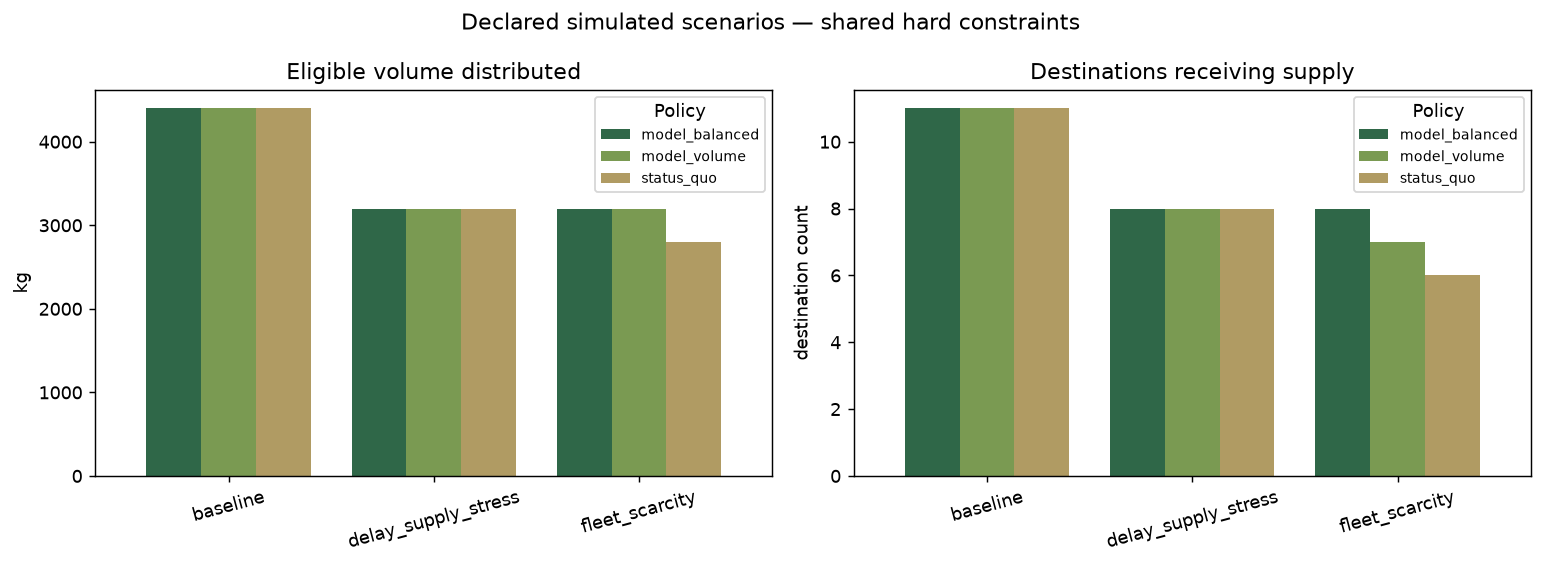

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for axis, metric, title, label in [
    (axes[0], "distributed_kg", "Eligible volume distributed", "kg"),
    (axes[1], "destinations_served", "Destinations receiving supply", "destination count"),
]:
    chart = policy_table.pivot(index="scenario", columns="policy", values=metric)
    chart.plot.bar(ax=axis, color=["#2f6748", "#7a9a52", "#b09b63"], width=0.8)
    axis.set_title(title)
    axis.set_ylabel(label)
    axis.set_xlabel("")
    axis.tick_params(axis="x", rotation=15)
    axis.legend(title="Policy", fontsize=8)
fig.suptitle("Declared simulated scenarios — shared hard constraints", fontsize=12)
fig.tight_layout()
figure_path = run.workspace / "reports/notebook_scenario_comparison.png"
fig.savefig(figure_path, dpi=130, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(figure_path)))


## 3. Reproduce the Save the Load and FEFO/FIFO workflow

[scripts/freshness_demo.py](../scripts/freshness_demo.py) creates its own fresh offline simulation, replays stored sensor frames, computes quality decay, compares warehouse picks, and exercises a synthetic dispatch approval and driver update.

The script supplies an explicitly **synthetic demo dispatcher** to test the approval gate. That is software workflow verification, not an attestation that a real human reviewed food or approved a real shipment. No connected hardware, live telemetry stream or commercial truck-safety validation is claimed.


In [5]:
run.run_script("scripts/freshness_demo.py")
freshness = run.read_json("reports/freshness_demo.json")
freshness_expected = run.baseline_json("reports/freshness_demo.json")
assert freshness["passed"] is True
assert freshness["simulation"] is True
assert freshness["physical_hardware_connected"] is False
assert freshness["operator_database_modified"] is False
assert all(item["passed"] is True for item in freshness["checks"])

for field in ("baseline_reference_hours", "point_forward_hours", "conservative_case_hours"):
    np.testing.assert_allclose(
        freshness["quality"][field], freshness_expected["quality"][field],
        rtol=1e-8, atol=1e-8,
    )
quality_table = pd.Series({
    "baseline_reference_hours": freshness["quality"]["baseline_reference_hours"],
    "point_forward_hours": freshness["quality"]["point_forward_hours"],
    "chosen_parameter_conservative_hours": freshness["quality"]["conservative_case_hours"],
}, name="Simulated quality clock")
display(quality_table.to_frame())
display(pd.DataFrame(freshness["quality"]["sensitivity"]["cases"]))
print(freshness["quality"]["sensitivity"]["kind"])


C:\Users\ericp\Downloads\NAFSI\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"passed": true, "checks": 15, "error": null, "operator_database_modified": false}


,Simulated quality clock
baseline_reference_hours,9.000000
point_forward_hours,4.388540
chosen_parameter_conservative_hours,1.508948


,q10,equivalent_age_hours,remaining_reference_hours,remaining_hours_at_forecast_temperature
0,1.5,234.270082,5.729918,5.729918
1,2.0,235.611460,4.388540,4.388540
2,3.0,238.491052,1.508948,1.508948


chosen-parameter sensitivity; not a confidence interval or guaranteed bound


In [6]:
warehouse_rows = []
for strategy in ("fefo", "fifo"):
    actual = freshness["warehouse"][strategy]
    expected = freshness_expected["warehouse"][strategy]
    for metric in ("supplied_kg", "unmet_demand_kg", "projected_expiry_exposure_kg"):
        np.testing.assert_allclose(actual[metric], expected[metric], rtol=1e-8, atol=1e-8)
    assert actual["priority_lot_ids"] == expected["priority_lot_ids"]
    warehouse_rows.append({
        "strategy": strategy,
        "supplied_kg": actual["supplied_kg"],
        "unmet_demand_kg": actual["unmet_demand_kg"],
        "modeled_expiry_exposure_kg": actual["projected_expiry_exposure_kg"],
        "first_priority_lot": actual["priority_lot_ids"][0],
    })
display(pd.DataFrame(warehouse_rows).set_index("strategy"))
display(pd.DataFrame(freshness["checks"]))
display(pd.Series(freshness["rescue_before_approval"], name="Rescue before synthetic approval").to_frame())
display(pd.Series(freshness["approval"], name="Synthetic approval receipt").to_frame())
display(pd.Series(freshness["driver"], name="Simulated driver after approval/new frame").to_frame())


,supplied_kg,unmet_demand_kg,modeled_expiry_exposure_kg,first_priority_lot
strategy,,,,
fefo,6400.0,1100.0,0.0,L05
fifo,6400.0,1100.0,1500.0,L12


,name,passed
0,verified fresh isolated offline runtime,True
1,actual eligible demonstration candidate exists,True
2,baseline quality has supported coverage,True
3,no assignment published by experiment creation,True
4,heat consumes the remaining quality budget,True
5,conservative case is separate from point estimate,True
6,rescue automatically computes a concrete feasi...,True
7,FEFO and FIFO use actual independently reviewe...,True
8,sensor replay does not change operational state,True
9,reading a stored experiment preserves SQLite a...,True


,Rescue before synthetic approval
shipment_id,SH05
original_destination,St. Louis destination 5 (simulated)
required_hours,4.052
selected_destination_id,D06
plan_summary,"{'assignments_count': 12, 'total_logistics_cos..."


,Synthetic approval receipt
actor,Synthetic demo dispatcher
reason,Isolated reproducible quality-rescue exercise;...
approved_at,2026-11-02T20:13:37.542554+00:00
network_revision,1
assignments_count,12
selected_destination_id,D06
sensor_version,3
simulation,True


,Simulated driver after approval/new frame
truck_id,T05
shipment_id,SH05
destination_id,D06
freshness_reviews,[{'session_id': '207196ec-125d-4ce0-a4c5-5bafd...
readiness_status_after_new_frame,review_required


## 4. Interpretation and preserved state

The results reproduce the supplied numerical scenario and freshness comparisons. A shorter illustrative quality clock can suggest a reviewed rescue or change FEFO priorities; a predictive score alone cannot impose a mandatory hold. Held/recalled inventory remains excluded regardless of objective weights.

Scenario quantities, costs, travel estimates, inventory, demand, receiving acceptance and sensor readings are simulated. The conservative Q10 case is chosen-parameter sensitivity, not a confidence interval or a guaranteed safe shelf life.

The cell below verifies preservation of original input/report and operator-state bytes. The workspace retains the regenerated CSV/JSON, figures and execution logs; no result is automatically published into the running application.


In [7]:
display(pd.Series(study["limitations"], name="Decision-study limitations").to_frame())
display(run.verify_preservation())
execution_manifest = run.finish()
print("Isolated execution record saved; application reports remain unchanged.")


,Decision-study limitations
0,"Every supply-chain entity, demand, capacity, t..."
1,The FSIS model estimates selected surveillance...
2,Quality guidance uses the existing illustrativ...
3,Hard safety measures count held/recalled/ineli...
4,Unsent stock remains inventory. Projected qual...
5,Food security is represented by preserving eli...
6,Historical USDA county need is not used as a d...
7,The first-feasible comparator is an explicit r...
8,One-wave fixed truck/candidate allocation omit...
9,"All actions are review proposals. No dispatch,..."


{'passed': True,
 'changed_inputs': [],
 'operator_preserved': True,
 'raw_preserved': True,
 'changed_raw_inputs': []}

Isolated execution record saved; application reports remain unchanged.
